# Border-aware MLP density model vs the plain MLP (Metric A)

Same **Mixture Density Network** as `fit_MLP` (F = Normal(0, sigma), L = Gamma(-dtheta),
R = Gamma(+dtheta), fed by a `dtheta` history + the stimulus term `b = sin(bearing-to-dots)`),
but each input row also carries a **physical-dish wall covariate**:

`[dist_to_border_norm, sin(psi), cos(psi)]`,  psi = egocentric bearing to the dish centre.

Distance alone can't say *which way* to turn; `sin/cos(psi)` supply the inward direction, exactly
as `b` supplies the dots' direction. Two models, mirroring `fit_MLP` (`mode='basic'` and `'full'`,
both `stim_mode='simple'`): `mlp_border_basic` and `mlp_border_full`.

The payoff is Section 5: **does the wall covariate improve held-out density bits/bout vs the plain
MLP?** Baseline (`mlp_basic`/`mlp_full`) and border models run in the SAME leave-fish-out pipeline,
so the paired per-fish comparison is apples-to-apples. Batch equivalent: `scripts/fit_MLP_border.py`.

## 1. Setup & load border-aware records

In [1]:
import sys
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm, gamma as gamma_dist

ROOT = Path.cwd()
if not (ROOT / "data").exists() and (ROOT.parent / "data").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "scripts"))
import fit_MLP_border as MB, fit_MLP as M, evaluate as E, fit_hmm as H   # notebook & CLI share code

df = E.load_bouts(str(ROOT / "data" / "bouts_GsizeMotionSingle.csv"))
records = MB.build_border_records(df)            # baseline records + attached pose/border/dish
recs = list(records.values())
ctx = E.make_context(recs, cfg={})               # dt/dist pools for sampling
print(f"{len(recs)} fish, {sum(r.n for r in recs)} bouts")

# feature sanity: K=5 dtheta history + 1 stimulus (b) + 3 border -> D=9  (plain MLP is D=6)
cfg_feat = dict(K=5, stim_mode="simple", include_symbols=False,
                dth_scale=float(np.std(np.concatenate([r.dtheta for r in recs]))),
                rich_scales=None, use_border=True)
Xs, ys = MB.build_feature_sequences(recs, cfg_feat)
print("border feature matrix:", Xs.shape, "  (5 history + 1 stimulus + 3 border)")

15 fish, 70590 bouts
border feature matrix: (70590, 9)   (5 history + 1 stimulus + 3 border)


## 2. MLP-border-basic — 3 outputs (F/L/R weights; global symmetric emission)
Identical to `fit_MLP`'s MLP-basic, but the input row also carries the 3-column wall covariate.
The MLP outputs only the mixture weights; sigma, alpha, theta are shared scalars fit jointly.

border-basic: final val NLL 5.4184 | features D = 9 (border ON)


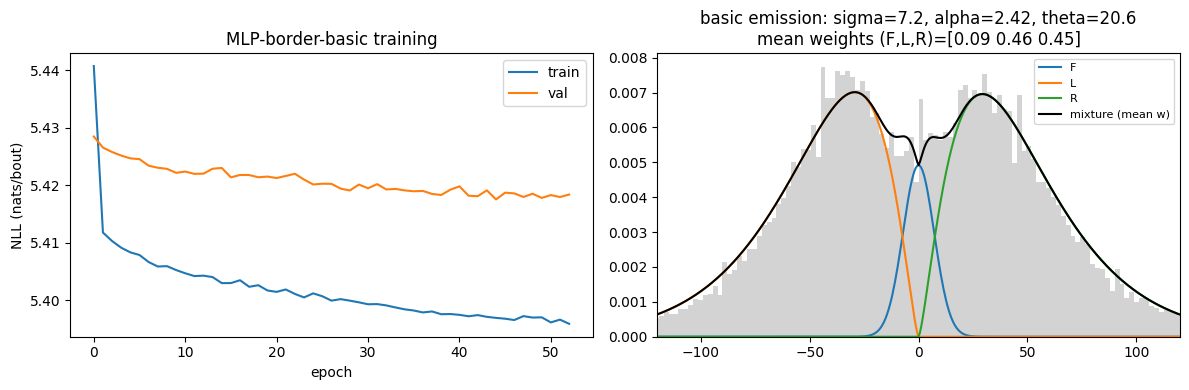

In [2]:
m_basic = MB.MLPBorderDensity(mode="basic", K=5, stim_mode="simple", hidden=64, epochs=80, seed=0)
m_basic.fit(recs, ctx)
print("border-basic: final val NLL", round(m_basic.history["val"][-1], 4),
      "| features D =", m_basic.config["n_features"], "(border ON)")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(m_basic.history["train"], label="train"); ax[0].plot(m_basic.history["val"], label="val")
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("NLL (nats/bout)"); ax[0].legend()
ax[0].set_title("MLP-border-basic training")

# emission overlay: global scalar params + MEAN predicted weights over all bouts
alld = np.concatenate([r.dtheta for r in recs])
wall = np.concatenate([M.predict_params(m_basic._model, MB.build_feature_matrix(r, m_basic._cfg_feat))[0]
                       for r in recs], axis=0)
wm = wall.mean(0)
_, sF, aL, tL, _, _ = M.predict_params(m_basic._model, MB.build_feature_matrix(recs[0], m_basic._cfg_feat))
sigma, alpha, theta = sF[0], aL[0], tL[0]
xg = np.linspace(-180, 180, 601)
pdf_f = wm[0] * norm.pdf(xg, 0, sigma)
pdf_l = np.where(xg < 0, wm[1] * gamma_dist.pdf(-xg, alpha, scale=theta), 0.0)
pdf_r = np.where(xg > 0, wm[2] * gamma_dist.pdf(xg, alpha, scale=theta), 0.0)
ax[1].hist(alld, bins=160, range=(-180, 180), density=True, color="lightgray")
ax[1].plot(xg, pdf_f, label="F"); ax[1].plot(xg, pdf_l, label="L"); ax[1].plot(xg, pdf_r, label="R")
ax[1].plot(xg, pdf_f + pdf_l + pdf_r, "k", lw=1.5, label="mixture (mean w)")
ax[1].set_xlim(-120, 120); ax[1].legend(fontsize=8)
ax[1].set_title(f"basic emission: sigma={sigma:.1f}, alpha={alpha:.2f}, theta={theta:.1f}\nmean weights (F,L,R)={wm.round(2)}")
plt.tight_layout(); plt.show()

## 3. MLP-border-full — 8 outputs (per-bout asymmetric params)
Per bout, the MLP predicts 3 weights + `[sigma_F, alpha_L, theta_L, alpha_R, theta_R]` (forward mean
fixed at 0). Heteroscedastic: the predictive shape now adapts to history, stimulus **and** wall geometry.

border-full: final val NLL 5.3589


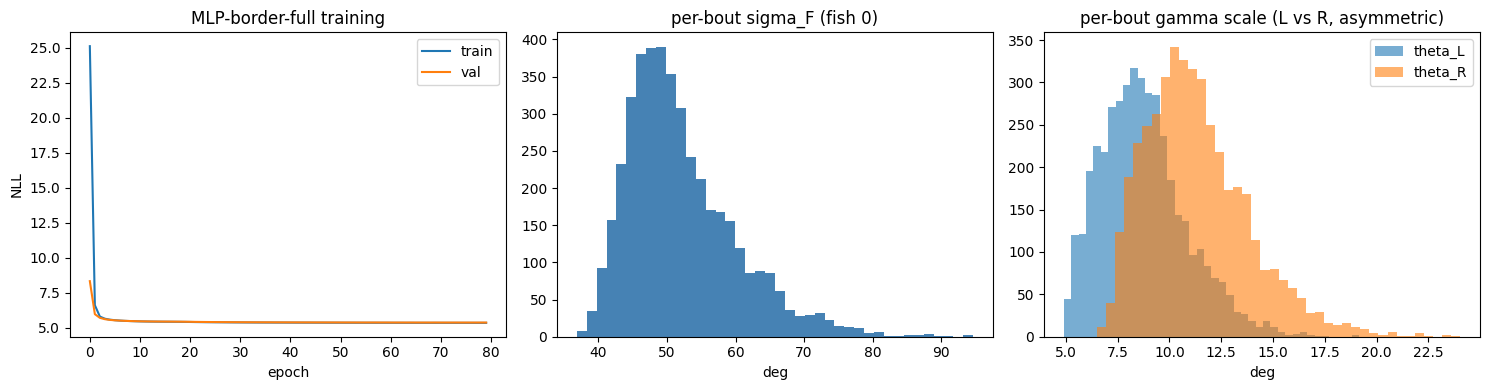

mean weights (F,L,R): [0.628 0.182 0.189]


In [3]:
m_full = MB.MLPBorderDensity(mode="full", K=5, stim_mode="simple", hidden=64, epochs=80, seed=0)
m_full.fit(recs, ctx)
print("border-full: final val NLL", round(m_full.history["val"][-1], 4))

# per-bout parameter variation on one fish (heteroscedasticity)
r = recs[0]
w, sF, aL, tL, aR, tR = M.predict_params(m_full._model, MB.build_feature_matrix(r, m_full._cfg_feat))
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(m_full.history["train"], label="train"); ax[0].plot(m_full.history["val"], label="val")
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("NLL"); ax[0].legend(); ax[0].set_title("MLP-border-full training")
ax[1].hist(sF, bins=40, color="steelblue"); ax[1].set_xlabel("deg")
ax[1].set_title(f"per-bout sigma_F (fish {r.fish_id})")
ax[2].hist(tL, bins=40, alpha=0.6, label="theta_L"); ax[2].hist(tR, bins=40, alpha=0.6, label="theta_R")
ax[2].set_xlabel("deg"); ax[2].legend(); ax[2].set_title("per-bout gamma scale (L vs R, asymmetric)")
plt.tight_layout(); plt.show()
print("mean weights (F,L,R):", w.mean(0).round(3))

## 4. Generate synthetic trajectories (autoregressive)
`sample` free-runs the MLP: each `dtheta` is drawn from the predicted mixture and fed back as history.
The stimulus **and the wall covariate are teacher-forced from the real fish** (`dt`/`distance` resampled
from empirical pools). So this shows the covariate's *predictive* value; it does NOT yet close the
position loop (feeding the generated trajectory's own wall distance back) -- that containment step is the
separate, deferred plan.

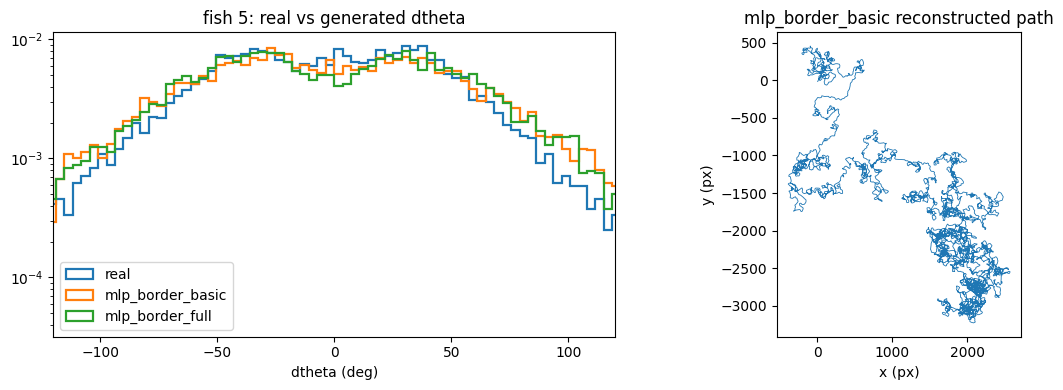

In [4]:
rng = np.random.default_rng(1)
r = records[5]
gen_b = m_basic.sample(r, rng)
gen_f = m_full.sample(r, rng)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for lab, d in [("real", r.dtheta), ("mlp_border_basic", gen_b["dtheta"]), ("mlp_border_full", gen_f["dtheta"])]:
    ax[0].hist(d, bins=100, range=(-180, 180), density=True, histtype="step", lw=1.6, label=lab)
ax[0].set_yscale("log"); ax[0].set_xlim(-120, 120); ax[0].set_xlabel("dtheta (deg)")
ax[0].legend(); ax[0].set_title(f"fish {r.fish_id}: real vs generated dtheta")
x, y, _ = H.reconstruct_xy(gen_b["dtheta"], gen_b["distance_px"])
ax[1].plot(x, y, lw=0.6); ax[1].set_aspect("equal")
ax[1].set_xlabel("x (px)"); ax[1].set_ylabel("y (px)"); ax[1].set_title("mlp_border_basic reconstructed path")
plt.tight_layout(); plt.show()

## 5. Does the wall covariate help? (Metric A -- border vs plain MLP)
Leave-3-fish-out CV of held-out **density bits/bout** (lower = better). We run the plain MLPs
(`mlp_basic`/`mlp_full`) and the border MLPs (`mlp_border_basic`/`mlp_border_full`) through the
IDENTICAL pipeline on the SAME records, then read the **paired per-fish** comparison of each border
model against its plain counterpart. `cfg=dict(mlp_epochs=40)` caps per-fold training (20 MLP fits);
raise it for final numbers.

  fold 0: trained on 12 fish, scored [2, 4, 6]
  fold 1: trained on 12 fish, scored [7, 9, 11]
  fold 2: trained on 12 fish, scored [3, 5, 13]
  fold 3: trained on 12 fish, scored [8, 10, 14]
  fold 4: trained on 12 fish, scored [0, 1, 12]


,model,metric,mean,mean_lo,mean_hi,median,n_fish
2,mlp_border_full,bits_per_bout,7.7754,7.6848,7.8846,7.7426,15
3,mlp_full,bits_per_bout,7.8150,7.7251,7.9262,7.7949,15
1,mlp_border_basic,bits_per_bout,7.8244,7.7292,7.9468,7.7795,15
0,mlp_basic,bits_per_bout,7.8529,7.7554,7.9779,7.8161,15


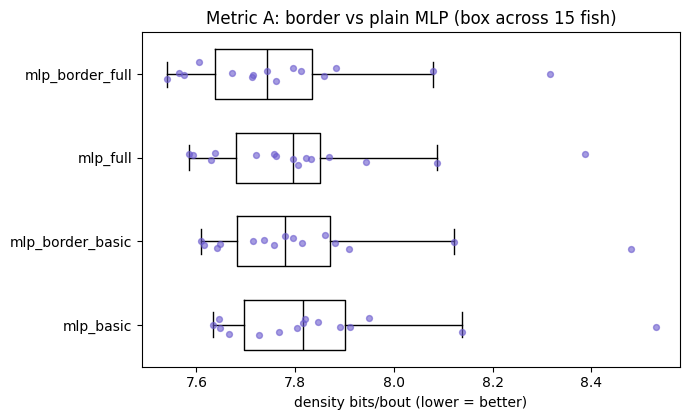

Paired per-fish comparison (higher nats/bout = better) -- does the wall covariate help?


{'model_a': 'mlp_border_basic',
 'model_b': 'mlp_basic',
 'metric': 'nats_per_bout',
 'n_fish': 15,
 'prefer_a': 15,
 'prefer_b': 0,
 'ties': 0,
 'median_delta': 0.021373748779296875,
 'delta_lo': 0.016204357147216797,
 'delta_hi': 0.022257328033447266,
 'wilcoxon_p': 6.103515625e-05,
 'sign_test_p': 6.103515625e-05}

{'model_a': 'mlp_border_full',
 'model_b': 'mlp_full',
 'metric': 'nats_per_bout',
 'n_fish': 15,
 'prefer_a': 15,
 'prefer_b': 0,
 'ties': 0,
 'median_delta': 0.03096628189086914,
 'delta_lo': 0.0189056396484375,
 'delta_hi': 0.03454399108886719,
 'wilcoxon_p': 6.103515625e-05,
 'sign_test_p': 6.103515625e-05}

In [5]:
folds = E.make_folds(sorted(records), n_folds=5, seed=0)
facs = [lambda: M.MLPDensity(mode="basic", K=5, stim_mode="simple", hidden=64),
        lambda: M.MLPDensity(mode="full",  K=5, stim_mode="simple", hidden=64),
        lambda: MB.MLPBorderDensity(mode="basic", K=5, stim_mode="simple", hidden=64),
        lambda: MB.MLPBorderDensity(mode="full",  K=5, stim_mode="simple", hidden=64)]
likA = E.add_skill_scores(E.cross_validate_likelihood(records, facs, folds,
                                                      cfg=dict(mlp_epochs=40), verbose=True))
sumA = E.summarize(likA, metric="bits_per_bout")
display(sumA.round(4))

order = sumA.dropna(subset=["mean"]).sort_values("mean")["model"].tolist()
data = [likA.loc[likA.model == m, "bits_per_bout"].dropna().to_numpy() for m in order]
fig, ax = plt.subplots(figsize=(7, 0.7 * len(order) + 1.5))
ax.boxplot(data, vert=False, showfliers=False, widths=0.6, medianprops=dict(color="black"))
rng = np.random.default_rng(0)
for i, dv in enumerate(data):
    ax.scatter(dv, rng.normal(i + 1, 0.06, len(dv)), s=18, color="slateblue", alpha=0.6, zorder=3)
ax.set_yticks(range(1, len(order) + 1)); ax.set_yticklabels(order)
ax.set_xlabel("density bits/bout (lower = better)")
ax.set_title("Metric A: border vs plain MLP (box across 15 fish)"); ax.invert_yaxis()
plt.tight_layout(); plt.show()

print("Paired per-fish comparison (higher nats/bout = better) -- does the wall covariate help?")
display(E.paired_compare(likA, "mlp_border_basic", "mlp_basic", "nats_per_bout", higher_better=True))
display(E.paired_compare(likA, "mlp_border_full",  "mlp_full",  "nats_per_bout", higher_better=True))

## Notes & next steps
- **Reading it:** lower `bits_per_bout` wins; `paired_compare` gives the per-fish sign test
  (prefer >=13/15 agreement before declaring the covariate helps). A positive delta means wall-awareness
  improves next-bout prediction.
- **Covariate frame:** `psi` uses `f_ori_rad` (body orientation at onset), the same egocentric frame as
  the stimulus bearing `b`, and the SAME physical dish centre that defines `dist_to_border_norm`.
- **Sampling is teacher-forced** on the wall covariate (like the stimulus), so `sample`/`reconstruct_xy`
  here measure predictive value, not containment. Closing the position loop (+ a hard guardrail) so
  free-run rollouts stay inside the dish is the separate deferred plan.
- **Knobs:** `K`, `hidden`, `mlp_epochs`. To standardise `dist_to_border_norm` instead of feeding it raw,
  add a train-fold scale threaded through `_cfg_feat` exactly like `dth_scale`.